# **CMSC 320 Final Project Checkpoint 2:**

# **Data Cleaning/Processing and Simple Analysis**

## Part 1.1: Data Procesing - Cleaning the Stock_Price.csv

In [143]:
import pandas as pd
from datetime import datetime
import string
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

#load the csv of product stock and product info
stock_df = pd.read_csv("Stock_Price.csv")
product_df = pd.read_csv("Product_Info.csv")

#cleaning stock
#make City - taipei and new taipei city just New Taipei City
stock_df["City"] = stock_df["City"].replace("Taipei", "New Taipei City")

#make Industry - Internet Retail United States to Internet Retail
stock_df["Industry"] = stock_df["Industry"].replace("Internet Retail United States", "Internet Retail")

#Remove Sector, Website, CEO, Description columns

stock_df = stock_df.drop(columns=["Sector", "Website", "CEO", "Description", "ID"])
stock_df["Past_Year_Low"] = stock_df["52W_Low"]
stock_df = stock_df.drop(columns="52W_Low")
stock_df["Past_Year_High"] = stock_df["52W_High"]
stock_df = stock_df.drop(columns="52W_High")

#Remove dollar signs, make all dollar values floats

stock_df ["Market_Value"] = (stock_df["Market_Value"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

stock_df ["Current_Price"] = (stock_df["Current_Price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

#remove duplicate rows
stock_df.drop_duplicates(inplace=True)

#Display the dataset
stock_df



,Company_Name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Amazon.com, Inc.",Internet Retail,United States,Seattle,2379000578048.00,222.54,226.19,161.38,258.60
1,ASUSTeK Computer Inc.,Computer Hardware,Taiwan,New Taipei City,435257507840.00,586.00,584.00,441.00,745.00
2,Intel Corporation,Semiconductors,United States,Santa Clara,178922684416.00,37.51,37.81,17.67,44.02
3,HP Inc.,Computer Hardware,United States,Palo Alto,22890848256.00,24.49,24.74,21.21,35.28
4,Dell Technologies Inc.,Computer Hardware,United States,Round Rock,87467827200.00,130.51,129.98,66.25,168.08
5,Lenovo Group Limited,Computer Hardware,Hong Kong,Quarry Bay,15170897920.00,24.46,24.50,17.84,35.09
6,Acer Incorporated,Computer Hardware,Taiwan,New Taipei City,79514206208.00,26.45,26.70,26.20,40.95
7,Apple Inc.,Consumer Electronics,United States,Cupertino,4067898949632.00,274.11,278.28,169.21,288.62
9,"Samsung Electronics Co., Ltd.",Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
10,Sony Group Corporation,Consumer Electronics,Japan,Tokyo,158866636800.00,26.64,26.77,19.85,30.34


## Part 1.2: Data Procesing - Cleaning the Product_Info.csv

In [144]:
#reorder brand column to be first column in csv, and remove non essential columns
product_df = product_df[["brand", "prices.amountMax", "prices.amountMin", "prices.availability", "prices.condition", "prices.currency", "prices.merchant", "categories", "dateAdded", "dateUpdated", "name"]]

#standardize prices.availability and price condition
product_df["prices.condition"] = product_df["prices.condition"].replace(["New", "New other (see details)"], "new")
product_df["prices.condition"] = product_df["prices.condition"].replace(["Used", "used", "Seller Refurbished", "Manufacturer Refurbished", "Pre-Owned", "For parts", "not working" ], "refurbished")
product_df = product_df.fillna("unknown")
product_df["prices.availability"] = product_df["prices.availability"].replace(["TRUE", "yes", "Yes", "In Stock", "Special Order", "Limited Order"], "in stock")
product_df["prices.availability"] = product_df["prices.availability"].replace(["no", "No", "Discontinued", "Not In Stock", "More On The Way"], "out of stock")

#change company names

product_df["brand"] = product_df["brand"].replace("Amazon", "Amazon.com, Inc.")
product_df["brand"] = product_df["brand"].replace("ASUS", "ASUSTeK Computer Inc.")
product_df["brand"] = product_df["brand"].replace("Intel", "Intel Corporation")
product_df["brand"] = product_df["brand"].replace("HP", "HP Inc.")
product_df["brand"] = product_df["brand"].replace("Dell", "Dell Technologies Inc.")
product_df["brand"] = product_df["brand"].replace("Lenovo", "Lenovo Group Limited")
product_df["brand"] = product_df["brand"].replace("Acer", "Acer Incorporated")
product_df["brand"] = product_df["brand"].replace("Apple", "Apple Inc.")
product_df["brand"] = product_df["brand"].replace("Samsung", "Samsung Electronics Co., Ltd.")
product_df["brand"] = product_df["brand"].replace("Sony", "Sony Group Corporation")
product_df["brand"] = product_df["brand"].replace("MSI", "Micro-Star International Co., Ltd.")
product_df["brand"] = product_df["brand"].replace("Microsoft", "Microsoft Corporation")
product_df["brand"] = product_df["brand"].replace("LG", "LG Electronics Inc.")
product_df["brand"] = product_df["brand"].replace("Amd", "Advanced Micro Devices, Inc.")
product_df["brand"] = product_df["brand"].replace("Corsair", "Corsair Gaming, Inc.")
product_df["brand"] = product_df["brand"].replace("Western Digital", "Western Digital Corporation")
product_df["brand"] = product_df["brand"].replace("Logitech", "Logitech International S.A.")
product_df["brand"] = product_df["brand"].replace("NVIDIA", "NVIDIA Corporation")
product_df["brand"] = product_df["brand"].replace("Netgear", "NETGEAR, Inc.")
product_df["brand"] = product_df["brand"].replace("Google", "Alphabet Inc.")
product_df["brand"] = product_df["brand"].replace("Panasonic", "Panasonic Holdings Corporation")


#remove all products not produced by the focused on companies
product_df = product_df[product_df["brand"].isin([
    "ASUSTeK Computer Inc.", "Intel Corporation", "HP Inc.", "Dell Technologies Inc.",
    "Lenovo Group Limited", "Acer Incorporated", "Apple Inc.", "Samsung Electronics Co., Ltd.",
    "Sony Group Corporation", "Micro-Star International Co., Ltd.", "Microsoft Corporation",
    "Panasonic Holdings Corporation", "LG Electronics Inc.", "Advanced Micro Devices, Inc.",
    "Corsair Gaming, Inc.", "Western Digital Corporation", "Logitech International S.A.",
    "NVIDIA Corporation", "NETGEAR, Inc.", "Alphabet Inc.", "Amazon.com, Inc.",
])].reset_index(drop=True)

#remove all products not in usd
product_df = product_df[product_df["prices.currency"] == "USD"].reset_index(drop=True)

product_df.head(10)

,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...


## Part 1.3: Data Procesing - Combining the two .csv files into one

In [145]:
combined_df = product_df.merge(stock_df, left_on="brand", right_on="Company_Name", how="inner")
combined_df = combined_df.drop(columns=["Company_Name"])

combined_df.head(10)

,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02


## Part 2.1: Simple Analysis - 

count    5638.00
mean      796.63
std      1241.77
min         1.00
25%       131.22
50%       358.50
75%       999.99
max     19999.99
Name: avg_price, dtype: float64


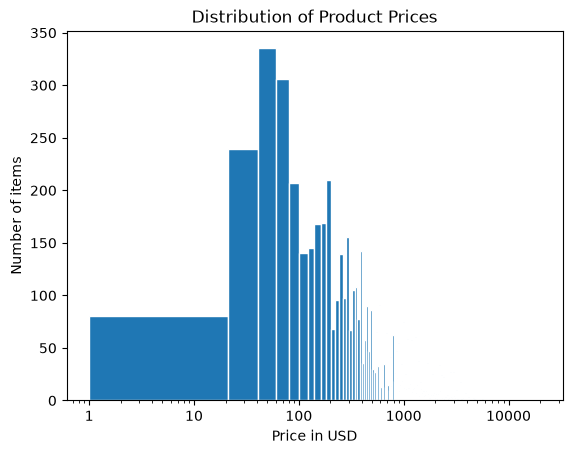

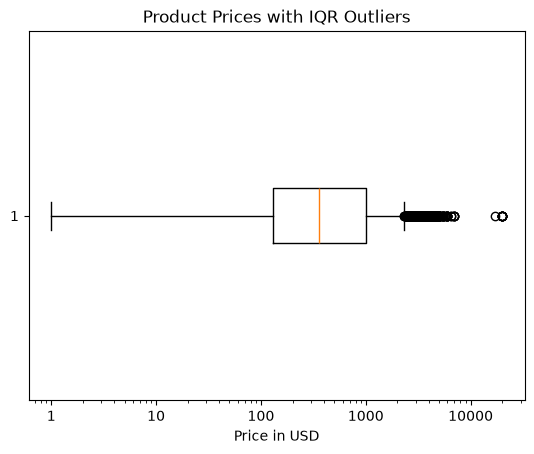

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

#calculate the average prive for each item
combined_df["avg_price"] = (combined_df["prices.amountMin"] + combined_df["prices.amountMax"]) / 2
price = combined_df["avg_price"]

#descriptive statistics for price 
print(price.describe())


plt.xscale("log")
plt.hist(price, bins= 1000, edgecolor="white")
plt.xscale("log")
plt.title("Distribution of Product Prices")
plt.xlabel("Price in USD")
plt.ylabel("Number of items")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()

plt.boxplot(price, orientation="horizontal")
plt.xscale("log")
plt.title("Product Prices with IQR Outliers")
plt.xlabel("Price in USD")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()